## Dependencies

In [1]:
import warnings
warnings.simplefilter("ignore", UserWarning)

In [2]:
import pandas as pd

In [3]:
import sys
sys.path.append('../')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs import vis

## Setup

In [ ]:
VERSION = 3

VAR_X = ['mean', 'median', 'mode']
DIR = f'../../results/v{VERSION}/gender/predictions/comparison/rs*/regression/_<VAR_X>/*'
METRIC = 'test_rmse'
ASCENDING = True

BEST_MODEL_ROOT = f'../../results/v{VERSION}/gender/predictions/best_modelx/rs<RANDOM_SEED>/'

In [5]:
vis.sns_paper_style()

## Data

In [6]:
df_results_mean = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mean'), include_fn=True)
df_results_median = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'median'), include_fn=True)
df_results_mode = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mode'), include_fn=True)
df_results = pd.concat([df_results_mean, df_results_median, df_results_mode], ignore_index=True)

# A few mods:
df_results.loc[:,'rs'] = df_results.fn.apply(lambda v: int(v.split('/rs')[-1].split('/')[0]))
df_results = df_results.query("rs != 12345").copy()
df_results.shape

(9207, 22)

In [7]:
df_results.columns

Index(['y', 'features_id', 'features', 'nfeatures', 'cat_features',
       'best_params', 'best_score', 'best_iteration', 'test_size',
       'random_state', 'loss_function', 'eval_metric', 'train_eval', 'test_r2',
       'test_rmse', 'all_r2', 'all_rmse', 'f_name', 'y_test', 'y_pred', 'fn',
       'rs'],
      dtype='object')

In [8]:
cols = ['y','features_id','features','nfeatures', 'train_eval','test_r2','test_rmse','rs']
df_results[cols].sort_values(METRIC, ascending=ASCENDING)

,y,features_id,features,nfeatures,train_eval,test_r2,test_rmse,rs
926,mean,894,"[ngender_r, ngender_n, gender_w, single_char, ...",7,0.097270,0.850307,0.093573,2
788,mean,1016,"[ngender_r, ngender_n, gender_n, gender_w, gen...",9,0.104353,0.849893,0.093702,2
797,mean,647,"[ngender_r, ngender_n, gender_n, gender_w, mea...",6,0.099451,0.849074,0.093957,2
441,mean,879,"[ngender_r, ngender_n, gender_n, single_char, ...",7,0.096131,0.848374,0.094175,2
852,mean,661,"[ngender_r, ngender_n, gender_n, gender_nw, me...",6,0.102582,0.847624,0.094408,2
...,...,...,...,...,...,...,...,...
8514,mode,35,"[gender_w, single_char]",2,0.269176,0.088985,0.312742,3
8554,mode,3,[gender_w],1,0.277138,0.086415,0.313183,3
8688,mode,5,[single_char],1,0.327874,0.001718,0.327378,3
7665,mode,5,[single_char],1,0.327874,0.001718,0.327378,2


In [9]:
best_id = df_results[METRIC].idxmin()
best_id

926

In [10]:
df_results.loc[[best_id], cols]

,y,features_id,features,nfeatures,train_eval,test_r2,test_rmse,rs
926,mean,894,"[ngender_r, ngender_n, gender_w, single_char, ...",7,0.09727,0.850307,0.093573,2


In [11]:
df_results.loc[best_id].features

['ngender_r',
 'ngender_n',
 'gender_w',
 'single_char',
 'mean_ngender_rn',
 'mean_ngender_nw',
 'mean_ngender_rnw']

In [12]:
df_results.loc[best_id]

y                                                              mean
features_id                                                     894
features          [ngender_r, ngender_n, gender_w, single_char, ...
nfeatures                                                         7
cat_features                                [gender_w, single_char]
best_params       {'depth': 2, 'learning_rate': 0.1, 'l2_leaf_re...
best_score        {'learn': {'RMSE': 0.09727013835394602}, 'vali...
best_iteration                                                   85
test_size                                                       0.2
random_state                                                      2
loss_function                                                  RMSE
eval_metric                                                    RMSE
train_eval                                                  0.09727
test_r2                                                    0.850307
test_rmse                                       

In [13]:
metric = df_results.loc[best_id].y
rs = df_results.loc[best_id].rs
f_name = DIR.replace('<VAR_X>',metric).replace('/*', "").replace('rs*',f'rs{rs}')
f_name = f"{f_name}/{df_results.loc[best_id].y}_{df_results.loc[best_id].features_id}"
f_name

'../../results/v3/gender/predictions/comparison/rs2/regression/_mean/mean_894'

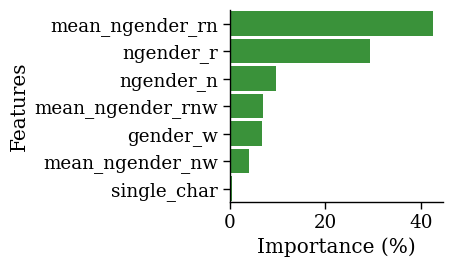

Total combinations of features: 1023


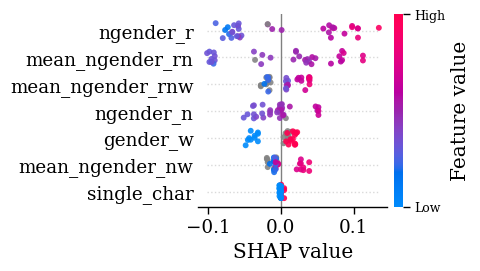

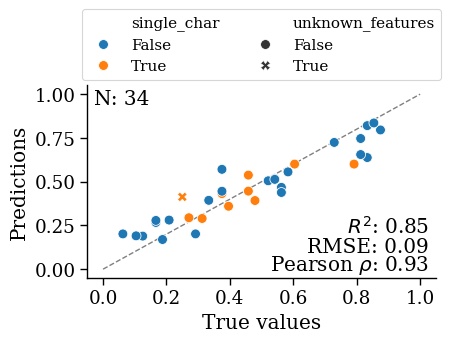

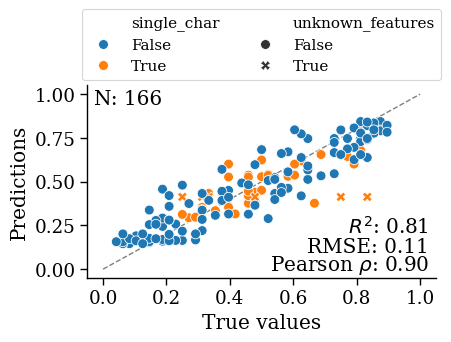

<Figure size 640x480 with 0 Axes>

In [14]:
fh = 2.5
spw = 2.75
spwshap = 2.65
spwscatter = 4.5

vis.replot_importance(f_name, regressor=True, figure_width=spw, figure_height=fh)
vis.replot_shap(f_name, regressor=True, figure_width=spwshap, figure_height=fh)
vis.replot_scatter(f_name, regressor=True, figure_width=spwscatter, figure_height=fh, legend_kwargs={'fontsize': 11, 'bbox_to_anchor': (0.5, 1.03)})

## Per run

In [15]:
df_best_per_run = df_results.loc[df_results.groupby('rs')[METRIC].idxmin(),:].sort_values(METRIC, ascending=ASCENDING)

In [16]:
# BEST per run
df_best_per_run[cols]

,y,features_id,features,nfeatures,train_eval,test_r2,test_rmse,rs
926,mean,894,"[ngender_r, ngender_n, gender_w, single_char, ...",7,0.097270,0.850307,0.093573,2
4883,median,975,"[ngender_r, ngender_n, gender_n, gender_w, gen...",8,0.122689,0.895295,0.095478,3
3262,mean,224,"[ngender_r, gender_w, gender_nw, single_char]",4,0.112366,0.824616,0.102887,1


Run id: 1
../../results/v3/gender/predictions/comparison/rs1/regression/_mean/mean_224


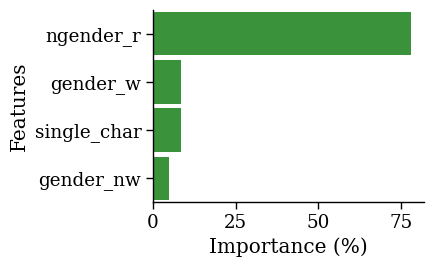

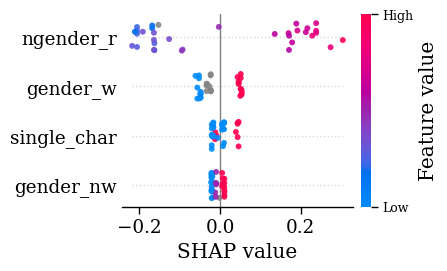

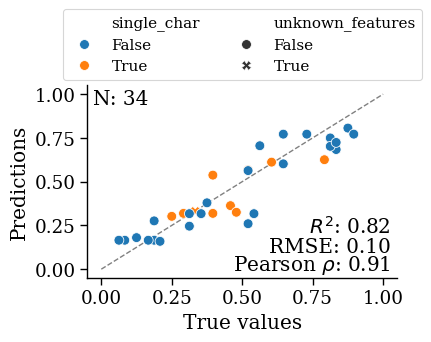

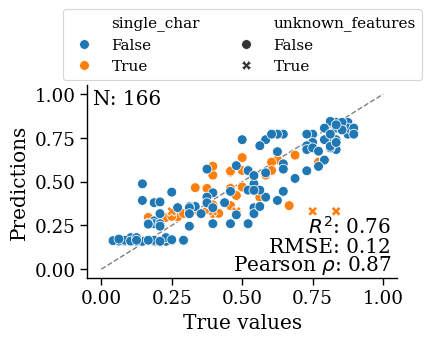

<Figure size 640x480 with 0 Axes>

In [17]:
rs = 1
tmp_run = df_best_per_run.query("rs == @rs")
f_name_rs = tmp_run.iloc[0].fn.replace('.json','')
best_overall = best_id == tmp_run.index[0]
print(f"Run id: {rs}" + (" (best overall)" if best_overall else ""))
print(f_name_rs)

spw = 3.5
spwshap = 3.25
spwscatter = 4.
vis.replot_importance(f_name_rs, regressor=True, figure_width=spw, figure_height=fh)
vis.replot_shap(f_name_rs, regressor=True, figure_width=spwshap, figure_height=fh)
vis.replot_scatter(f_name_rs, regressor=True, figure_width=spwscatter, figure_height=fh, legend_kwargs={'fontsize': 11, 'bbox_to_anchor': (0.5, 1.03)})

Run id: 2 (best overall)
../../results/v3/gender/predictions/comparison/rs2/regression/_mean/mean_894


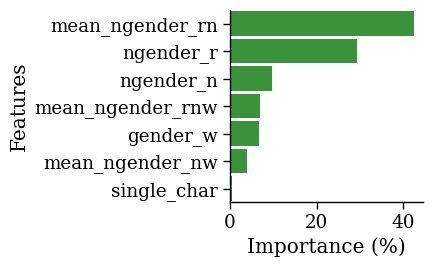

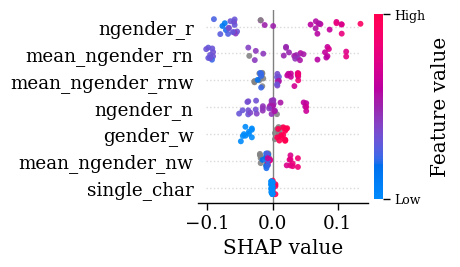

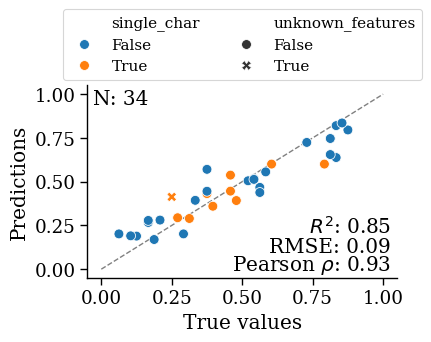

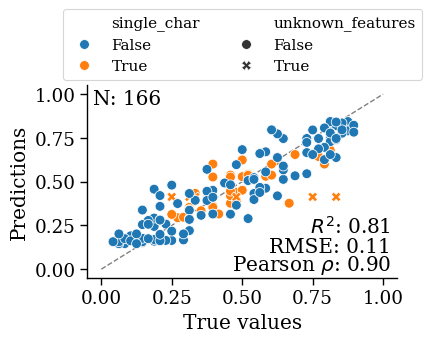

<Figure size 640x480 with 0 Axes>

In [18]:
rs = 2
tmp_run = df_best_per_run.query("rs == @rs")
f_name_rs = tmp_run.iloc[0].fn.replace('.json','')
best_overall = best_id == tmp_run.index[0]
print(f"Run id: {rs}" + (" (best overall)" if best_overall else ""))
print(f_name_rs)

spw = 2.5
spwshap = 2.38
spwscatter = 4.
vis.replot_importance(f_name_rs, regressor=True, figure_width=spw, figure_height=fh)
vis.replot_shap(f_name_rs, regressor=True, figure_width=spwshap, figure_height=fh)
vis.replot_scatter(f_name_rs, regressor=True, figure_width=spwscatter, figure_height=fh, legend_kwargs={'fontsize': 11, 'bbox_to_anchor': (0.5, 1.03)})

Run id: 3
../../results/v3/gender/predictions/comparison/rs3/regression/_median/median_975


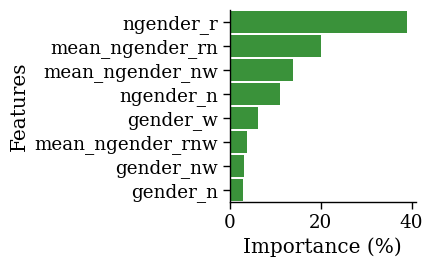

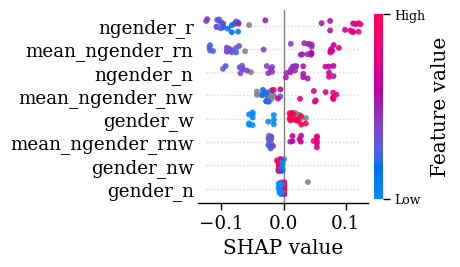

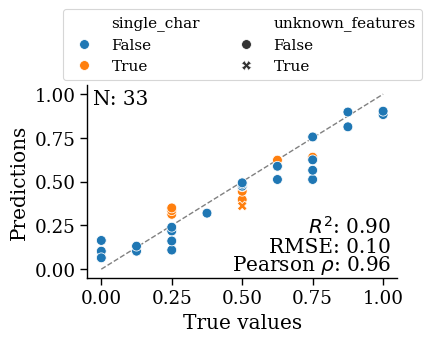

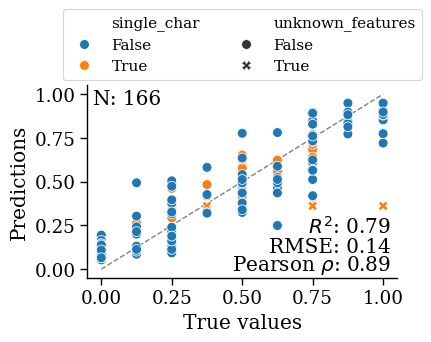

<Figure size 640x480 with 0 Axes>

In [19]:
rs = 3
tmp_run = df_best_per_run.query("rs == @rs")
f_name_rs = tmp_run.iloc[0].fn.replace('.json','')
best_overall = best_id == tmp_run.index[0]
print(f"Run id: {rs}" + (" (best overall)" if best_overall else ""))
print(f_name_rs)

spw = 2.4
spwshap = 2.38
spwscatter = 4.
vis.replot_importance(f_name_rs, regressor=True, figure_width=spw, figure_height=fh)
vis.replot_shap(f_name_rs, regressor=True, figure_width=spwshap, figure_height=fh)
vis.replot_scatter(f_name_rs, regressor=True, figure_width=spwscatter, figure_height=fh, legend_kwargs={'fontsize': 11, 'bbox_to_anchor': (0.5, 1.03)})